# Matrizes dos parâmetros

DBO, DQO e SST são grandezas contínuas. A matriz que coloca cada uma contra as outras é a correlação de Pearson, não uma matriz de confusão: esta última compara classes previstas e observadas.

Há duas matrizes. A primeira usa só a entrada da planta, que é o recorte dos modelos. A segunda usa as mesmas três grandezas em todos os pontos medidos. Cada célula usa os dias em que o par existe; dias sem uma das duas medidas não entram naquela célula.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "medium",
})

ENTRADA = ["DBO-E", "DQO-E", "SS-E"]
TODOS = [
    "DBO-E", "DBO-P", "DBO-D", "DBO-S",
    "DQO-E", "DQO-D", "DQO-S",
    "SS-E", "SS-P", "SS-D", "SS-S",
]
ROTULOS = {
    "DBO-E": "DBO entrada",
    "DBO-P": "DBO primário",
    "DBO-D": "DBO secundário",
    "DBO-S": "DBO saída",
    "DQO-E": "DQO entrada",
    "DQO-D": "DQO secundário",
    "DQO-S": "DQO saída",
    "SS-E": "SST entrada",
    "SS-P": "SST primário",
    "SS-D": "SST secundário",
    "SS-S": "SST saída",
}


def raiz_repositorio() -> Path:
    aqui = Path.cwd().resolve()
    for candidato in [aqui, *aqui.parents]:
        if (candidato / "data" / "water-treatment-plant" / "water-treatment.data").exists():
            return candidato
    raise FileNotFoundError("Repositório SoftSensor não encontrado.")


RAIZ = raiz_repositorio()
sys.path.insert(0, str(RAIZ / "modelo"))
from dados import carregar

FIGURAS = RAIZ / "docs" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
serie = carregar()


## Entrada

Só `DBO-E`, `DQO-E` e `SS-E`.


dias com as três medidas da entrada: 498


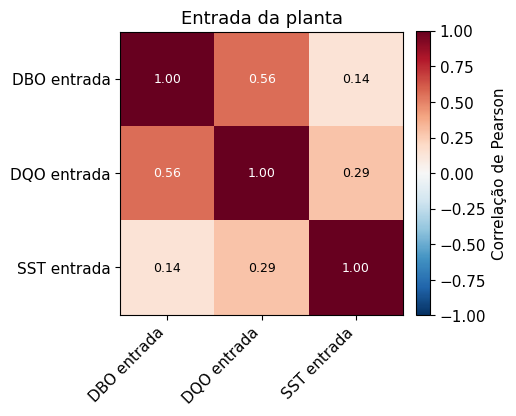

,DBO-E,DQO-E,SS-E
DBO-E,504,499,503
DQO-E,499,521,520
SS-E,503,520,526


In [2]:
def matriz(colunas):
    bloco = serie[colunas]
    return bloco.corr(), bloco.notna().astype(int).T @ bloco.notna().astype(int)


def desenhar(correlacao, contagem, nome, titulo):
    rotulos = [ROTULOS[coluna] for coluna in correlacao.columns]
    lado = 1.15 * len(rotulos) + 1.6
    fig, ax = plt.subplots(figsize=(lado, lado * 0.86))
    imagem = ax.imshow(correlacao.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(rotulos)), rotulos, rotation=45, ha="right")
    ax.set_yticks(range(len(rotulos)), rotulos)
    ax.set_title(titulo)
    for i in range(len(rotulos)):
        for j in range(len(rotulos)):
            valor = correlacao.iloc[i, j]
            cor_texto = "white" if abs(valor) > 0.55 else "black"
            ax.text(j, i, f"{valor:.2f}", ha="center", va="center", color=cor_texto, fontsize=9)
    fig.colorbar(imagem, ax=ax, fraction=0.046, pad=0.04).set_label("Correlação de Pearson")
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nome}.pdf")
    fig.savefig(FIGURAS / f"{nome}.png", dpi=150)
    plt.show()
    return contagem


corr_entrada, n_entrada = matriz(ENTRADA)
print(f"dias com as três medidas da entrada: {int(serie[ENTRADA].dropna().shape[0])}")
n_plot = desenhar(
    corr_entrada,
    n_entrada,
    "correlacao_entrada",
    "Entrada da planta",
)
n_plot


## Todos os pontos

DBO, DQO e SST na entrada, no primário, no secundário e na saída. Não há DQO no primário. Sólidos voláteis e desempenhos ficam de fora.


dias com as onze medidas ao mesmo tempo: 446


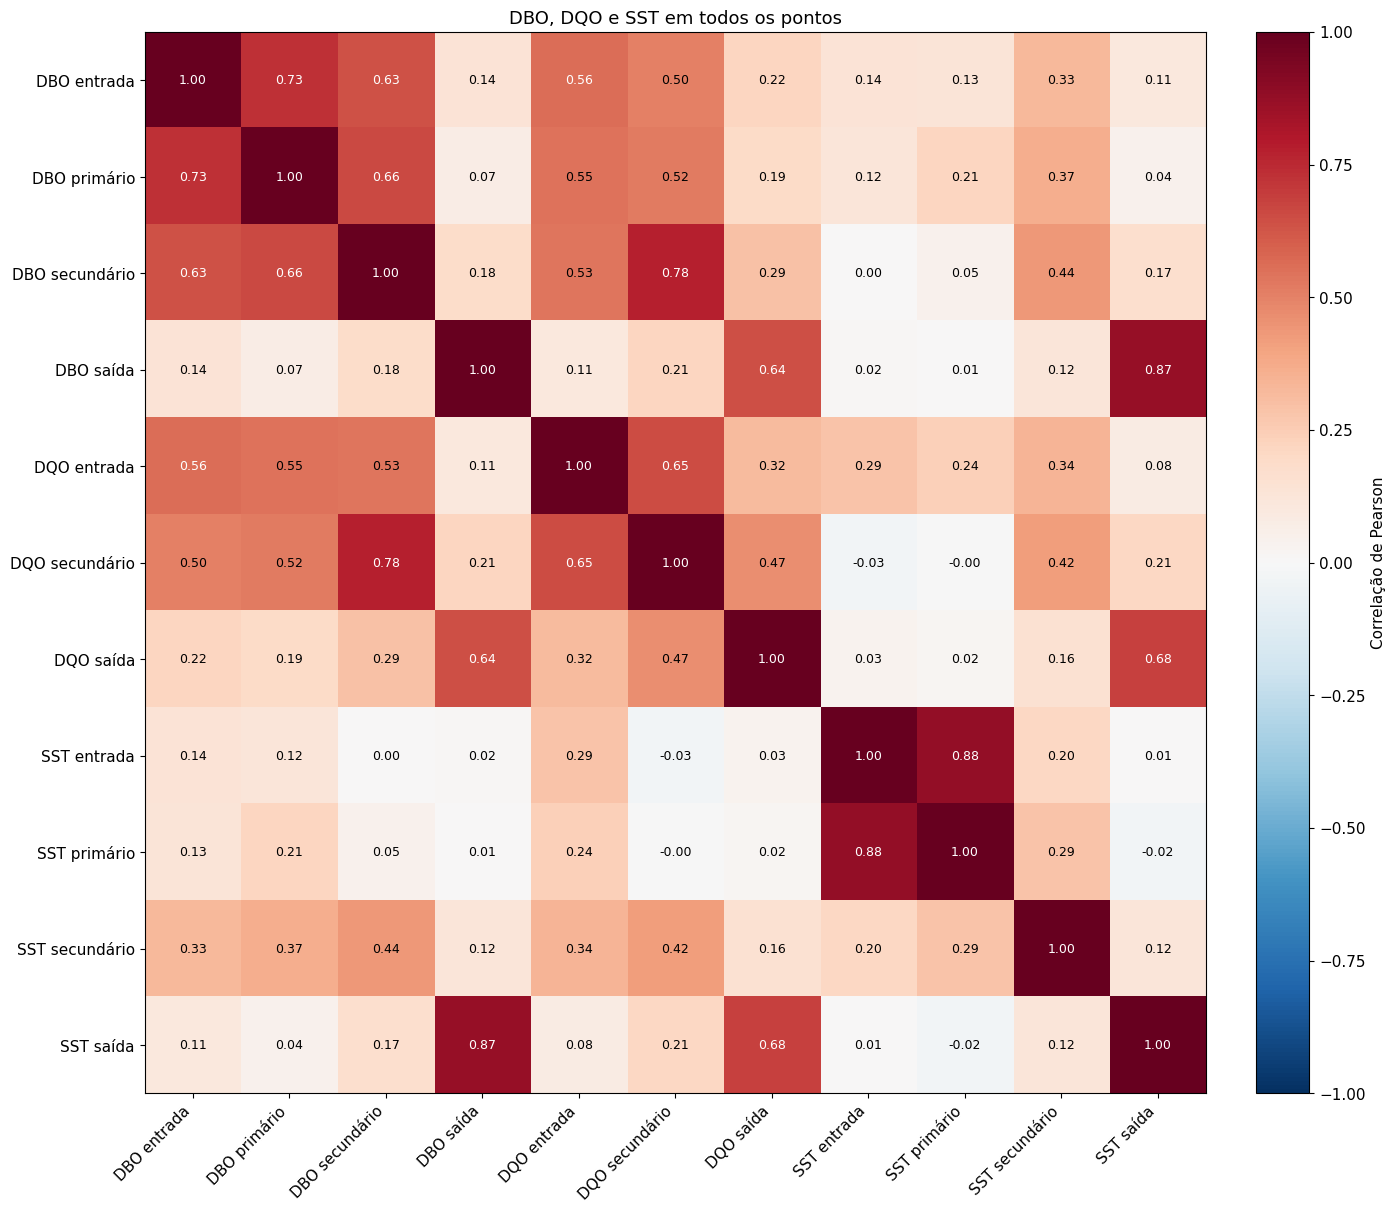

,DBO-E,DBO-P,DBO-D,DBO-S,DQO-E,DQO-D,DQO-S,SS-E,SS-P,SS-D,SS-S
DBO-E,504,484,491,496,499,495,487,503,504,502,500
DBO-P,484,487,480,479,482,478,470,486,487,485,483
DBO-D,491,480,499,491,493,490,483,498,499,497,496
DBO-S,496,479,491,504,498,495,490,503,504,502,501
DQO-E,499,482,493,498,521,515,506,520,521,519,516
DQO-D,495,478,490,495,515,518,503,517,518,516,513
DQO-S,487,470,483,490,506,503,509,508,509,507,506
SS-E,503,486,498,503,520,517,508,526,526,525,522
SS-P,504,487,499,504,521,518,509,526,527,525,522
SS-D,502,485,497,502,519,516,507,525,525,525,522


In [3]:
corr_todos, n_todos = matriz(TODOS)
print(f"dias com as onze medidas ao mesmo tempo: {int(serie[TODOS].dropna().shape[0])}")
n_plot = desenhar(
    corr_todos,
    n_todos,
    "correlacao_pontos",
    "DBO, DQO e SST em todos os pontos",
)
n_plot
